# Imprting Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset, DatasetDict
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, SimpleRNN, LSTM, GRU, Embedding, Dropout, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.metrics import confusion_matrix

# Load Dataset

In [2]:
raw=load_dataset('dair-ai/emotion',name="unsplit", split='train')
raw

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

unsplit/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 26.9MB            

unsplit/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/416809 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'label'],
    num_rows: 416809
})

In [3]:
target_column = "label"

In [4]:
test_split = raw.train_test_split(test_size=0.2, seed=42, stratify_by_column=target_column)
test_split

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 333447
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 83362
    })
})

In [5]:
val_test_split= test_split["test"].train_test_split(test_size=0.5, seed=42, stratify_by_column=target_column)
val_test_split

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 41681
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 41681
    })
})

In [6]:
df = DatasetDict({
    "train": test_split["train"],
    "validation": val_test_split["train"],
    "test": val_test_split["test"]
})
df

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 333447
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 41681
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 41681
    })
})

In [7]:
train_text=df['train']['text']
train_label=df['train']['label']

In [8]:
val_text=df['validation']['text']
val_label=df['validation']['label']

In [9]:
test_text=df['test']['text']
test_label=df['test']['label']

In [10]:
label_names=df['train'].features['label'].names
label_names

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [11]:
df_train = pd.DataFrame(
    {
        'text'  : train_text,
        'label' : [label_names[i] for i in train_label]
    }
)

df_val = pd.DataFrame(
    {
        'text'  : val_text,
        'label' : [label_names[i] for i in val_label]
    }
)

df_test = pd.DataFrame(
    {
        'text'  : test_text,
        'label' : [label_names[i] for i in test_label]
    }
)

In [15]:
df_train.shape

(333447, 2)

In [16]:
df_val.shape

(41681, 2)

In [17]:
df_test.shape

(41681, 2)

# EDA

In [18]:
order=df_train['label'].value_counts().index

<Axes: xlabel='label', ylabel='count'>

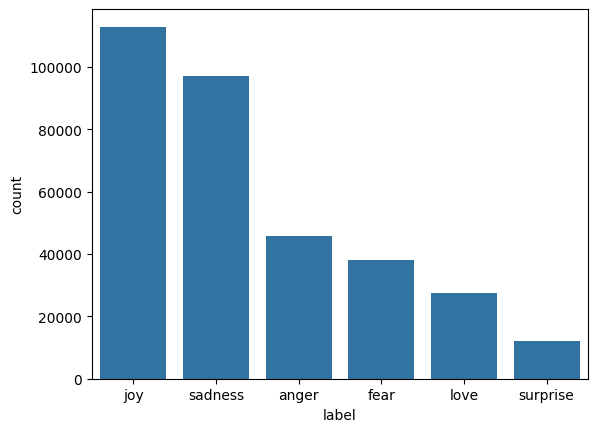

In [19]:
sns.countplot(data=df_train,x='label',order=order)

# Data Preprocessing

In [20]:
max_words=60000

In [21]:
tokenizer=Tokenizer(num_words=max_words,oov_token='<ukn>')
tokenizer.fit_on_texts(df_train['text'])
train_sequence=tokenizer.texts_to_sequences(df_train['text'])
val_sequence=tokenizer.texts_to_sequences(df_val['text'])
test_sequence=tokenizer.texts_to_sequences(df_test['text'])

In [22]:
len(tokenizer.word_index)

67866

In [23]:
max_len=max([len(seq) for seq in train_sequence])
padded_train_sequence = pad_sequences(train_sequence,maxlen=max_len,padding='post', truncating='post')
padded_val_sequence = pad_sequences(val_sequence,maxlen=max_len,padding='post', truncating='post')
padded_test_sequence = pad_sequences(test_sequence ,maxlen=max_len,padding='post', truncating='post')

In [24]:
max_len

178

In [25]:
train_labels = np.array(train_label)
val_labels = np.array(val_label)
test_labels  = np.array(test_label)

In [26]:
num_classes = len(np.unique(train_labels))

# Assiginning Class Weight
due to class imbalance problem

In [27]:
from sklearn.utils import class_weight

class_weights=class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels),
    y=train_labels
)

class_weight_dict=dict(enumerate(class_weights))

In [28]:
class_weight_dict

{0: np.float64(0.5732343809631868),
 1: np.float64(0.4924503557725537),
 2: np.float64(2.010436638570343),
 3: np.float64(1.2119880490251669),
 4: np.float64(1.455973277443018),
 5: np.float64(4.639714476540324)}

# Bidirectional Models

## BiGRU

In [54]:
BiGRU=Sequential()

In [55]:
BiGRU.add(Input(shape=(max_len,)))
BiGRU.add(Embedding(input_dim=max_words, output_dim=256))
BiGRU.add(Bidirectional(GRU(units=128, return_sequences=True)))
BiGRU.add(Dropout(0.3))
BiGRU.add(Bidirectional(GRU(units=64)))
BiGRU.add(Dropout(0.3))
BiGRU.add(Dense(units=num_classes, activation='softmax'))

In [56]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [57]:
checkpoint_path_bigru = '/content/bigru_model.keras'

bigru_checkpoint = ModelCheckpoint(
    checkpoint_path_bigru,
    monitor='val_loss',
    verbose=1,
    save_best_only=True,
    mode='min'
)

In [58]:
BiGRU.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [59]:
BiGRU.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 178, 256)       │    15,360,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_6 (Bidirectional) │ (None, 178, 256)       │       296,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 178, 256)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_7 (Bidirectional) │ (None, 128)            │       123,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,780,870 (60.20 MB)

 Trainable params: 15,780,870 (60.20 MB)

 Non-trainable params: 0 (0.00 B)

In [60]:
BiGRU_history=BiGRU.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_val_sequence, val_labels),
    epochs = 25,
    batch_size=64,
    class_weight=class_weight_dict,
    callbacks=[early_stopping,bigru_checkpoint]
)

Epoch 1/25
5211/5211 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.8391 - loss: 0.3781
Epoch 1: val_loss improved from None to 0.13456, saving model to /content/bigru_model.keras

Epoch 1: finished saving model to /content/bigru_model.keras
5211/5211 ━━━━━━━━━━━━━━━━━━━━ 243s 46ms/step - accuracy: 0.9143 - loss: 0.1940 - val_accuracy: 0.9400 - val_loss: 0.1346
Epoch 2/25
5211/5211 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.9410 - loss: 0.1208
Epoch 2: val_loss improved from 0.13456 to 0.12051, saving model to /content/bigru_model.keras

Epoch 2: finished saving model to /content/bigru_model.keras
5211/5211 ━━━━━━━━━━━━━━━━━━━━ 241s 46ms/step - accuracy: 0.9404 - loss: 0.1201 - val_accuracy: 0.9405 - val_loss: 0.1205
Epoch 3/25
5211/5211 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.9418 - loss: 0.1121
Epoch 3: val_loss improved from 0.12051 to 0.11447, saving model to /content/bigru_model.keras

Epoch 3: finished saving model to /content/bigru_model.keras
5211/5211 ━━━━━━━━━━━

In [61]:
bigru_loss, bigru_accuracy = BiGRU.evaluate(padded_test_sequence, test_labels)
print(f"BiGRU Loss: {bigru_loss}")
print(f"BiGRU Accuracy: {bigru_accuracy}")

1303/1303 ━━━━━━━━━━━━━━━━━━━━ 15s 12ms/step - accuracy: 0.9393 - loss: 0.1139
BiGRU Loss: 0.11385410279035568
BiGRU Accuracy: 0.9393488764762878


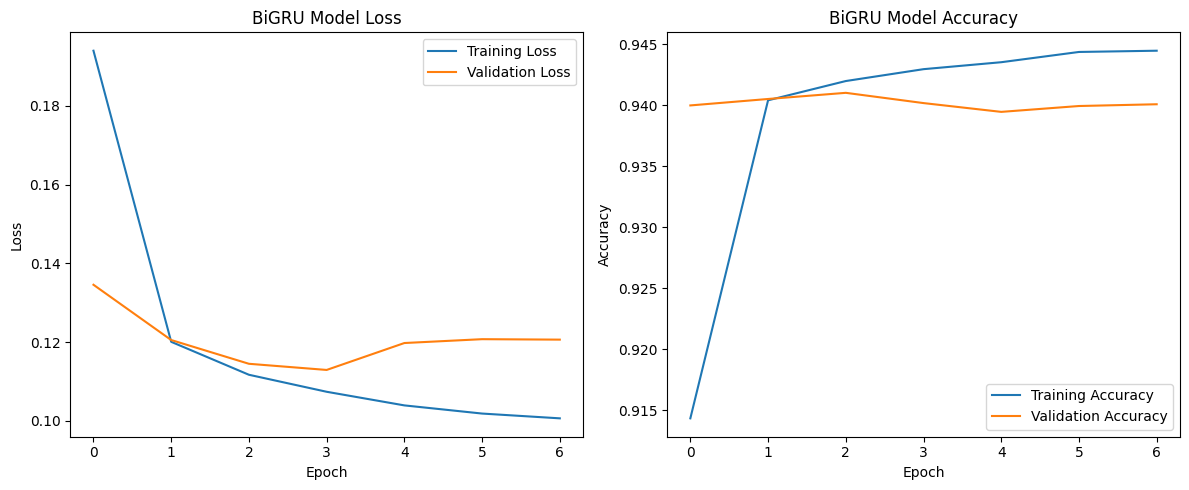

In [62]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(BiGRU_history.history['loss'], label='Training Loss')
plt.plot(BiGRU_history.history['val_loss'], label='Validation Loss')
plt.title('BiGRU Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(BiGRU_history.history['accuracy'], label='Training Accuracy')
plt.plot(BiGRU_history.history['val_accuracy'], label='Validation Accuracy')
plt.title('BiGRU Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()

plt.tight_layout()
plt.show()

## BiLSTM

In [45]:
BiLSTM=Sequential()

In [46]:
BiLSTM.add(Input(shape=(max_len,)))
BiLSTM.add(Embedding(input_dim=max_words, output_dim=256))
BiLSTM.add(Bidirectional(LSTM(units=128, return_sequences=True)))
BiLSTM.add(Dropout(0.3))
BiLSTM.add(Bidirectional(LSTM(units=64)))
BiLSTM.add(Dropout(0.3))
BiLSTM.add(Dense(units=num_classes, activation='softmax'))

In [47]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [48]:
checkpoint_path_bilstm = '/content/bilstm_model.keras'

bilstm_checkpoint = ModelCheckpoint(
    checkpoint_path_bilstm,
    monitor='val_loss',
    verbose=1,
    save_best_only=True,
    mode='min'
)

In [49]:
BiLSTM.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 178, 256)       │    15,360,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_4 (Bidirectional) │ (None, 178, 256)       │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 178, 256)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_5 (Bidirectional) │ (None, 128)            │       164,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,919,366 (60.73 MB)

 Trainable params: 15,919,366 (60.73 MB)

 Non-trainable params: 0 (0.00 B)

In [50]:
BiLSTM.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [51]:
BiLSTM_history=BiLSTM.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_val_sequence, val_labels),
    epochs = 25,
    batch_size=64,
    class_weight=class_weight_dict,
    callbacks=[early_stopping,bilstm_checkpoint]
)

Epoch 1/25
5211/5211 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.8310 - loss: 0.4055
Epoch 1: val_loss improved from None to 0.12921, saving model to /content/bilstm_model.keras

Epoch 1: finished saving model to /content/bilstm_model.keras
5211/5211 ━━━━━━━━━━━━━━━━━━━━ 260s 49ms/step - accuracy: 0.9100 - loss: 0.2048 - val_accuracy: 0.9393 - val_loss: 0.1292
Epoch 2/25
5211/5211 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.9404 - loss: 0.1142
Epoch 2: val_loss improved from 0.12921 to 0.11726, saving model to /content/bilstm_model.keras

Epoch 2: finished saving model to /content/bilstm_model.keras
5211/5211 ━━━━━━━━━━━━━━━━━━━━ 257s 49ms/step - accuracy: 0.9402 - loss: 0.1125 - val_accuracy: 0.9403 - val_loss: 0.1173
Epoch 3/25
5210/5211 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.9420 - loss: 0.1054
Epoch 3: val_loss improved from 0.11726 to 0.11655, saving model to /content/bilstm_model.keras

Epoch 3: finished saving model to /content/bilstm_model.keras
5211/5211 ━━━━━

In [52]:
bilstm_loss, bilstm_accuracy = BiLSTM.evaluate(padded_test_sequence, test_labels)
print(f"BiLSTM Loss: {bilstm_loss}")
print(f"BiLSTM Accuracy: {bilstm_accuracy}")

1303/1303 ━━━━━━━━━━━━━━━━━━━━ 16s 12ms/step - accuracy: 0.9401 - loss: 0.1129
BiLSTM Loss: 0.11285816133022308
BiLSTM Accuracy: 0.9401165843009949


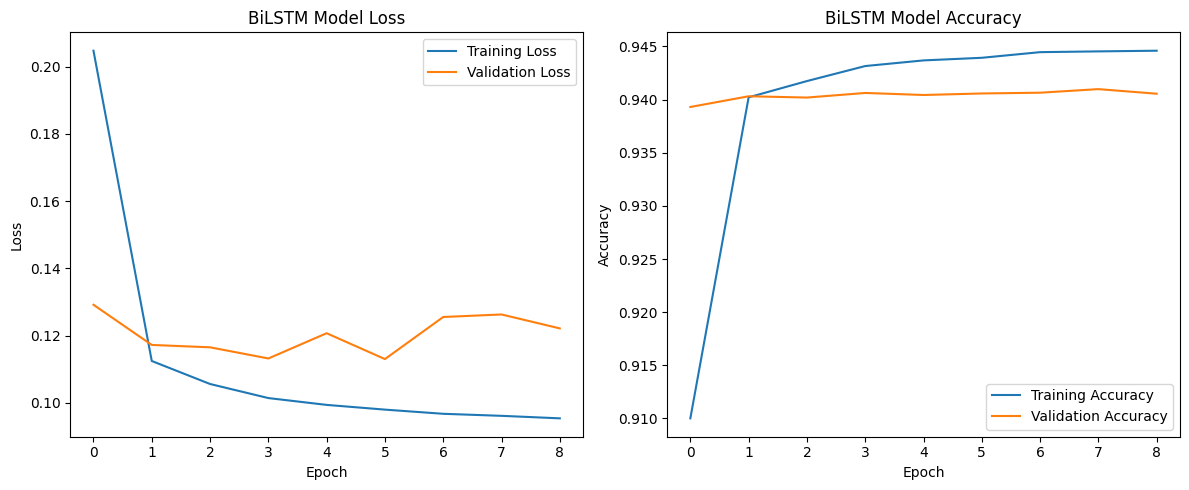

In [53]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(BiLSTM_history.history['loss'], label='Training Loss')
plt.plot(BiLSTM_history.history['val_loss'], label='Validation Loss')
plt.title('BiLSTM Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(BiLSTM_history.history['accuracy'], label='Training Accuracy')
plt.plot(BiLSTM_history.history['val_accuracy'], label='Validation Accuracy')
plt.title('BiLSTM Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()

plt.tight_layout()
plt.show()

In [63]:
result_df_2 = pd.DataFrame({
    'Model' : ['BiGRU', 'BiLSTM'],
    'Test Loss': [bigru_loss, bilstm_loss],
    'Test Accuracy': [bigru_accuracy, bilstm_accuracy]
    }).sort_values(by='Test Accuracy',ascending=False)
result_df_2

,Model,Test Loss,Test Accuracy
1,BiLSTM,0.112858,0.940117
0,BiGRU,0.113854,0.939349


# Evaluation

In [66]:
bigru_pred=np.argmax(BiGRU.predict(padded_test_sequence),axis=1)
bigru_pred

1303/1303 ━━━━━━━━━━━━━━━━━━━━ 14s 10ms/step


array([2, 3, 1, ..., 4, 3, 1])

In [67]:
cm=confusion_matrix(bigru_pred,test_labels)

<Axes: >

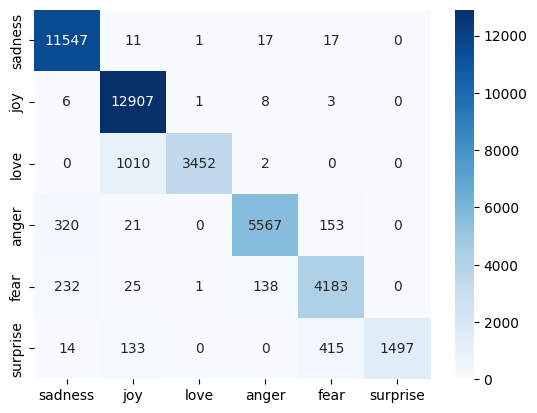

In [68]:
sns.heatmap(cm,annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)

In [69]:
bilstm_pred=np.argmax(BiLSTM.predict(padded_test_sequence),axis=1)
bilstm_pred

1303/1303 ━━━━━━━━━━━━━━━━━━━━ 15s 11ms/step


array([2, 3, 1, ..., 4, 3, 1])

In [72]:
cm2=confusion_matrix(bilstm_pred,test_labels)

<Axes: >

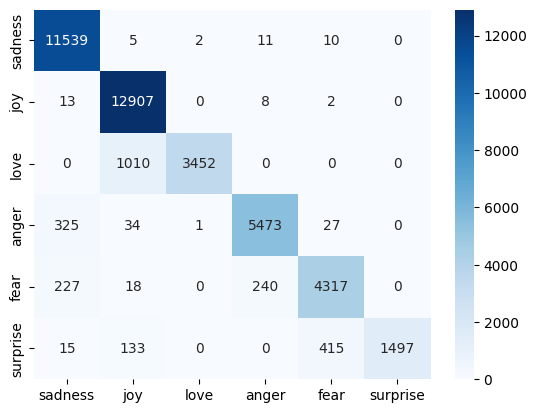

In [73]:
sns.heatmap(cm2,annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)

The BiGRU architecture was selected as the final model because it achieves a comparable predictive performance to the BiLSTM (approximately 94% test accuracy) while utilizing a simpler internal gating mechanism. This structural efficiency results in lower memory consumption, faster training times, and reduced inference latency, making it the most optimized and lightweight choice for our backend deployment.

# Testing

In [97]:
sample_texts = [
    "I feel incredibly happy and completely at peace today.",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I feel completely shocked by this unexpected news!"
]

sample_sequences = tokenizer.texts_to_sequences(sample_texts)
sample_padded_sequences = pad_sequences(sample_sequences, maxlen=max_len, padding='post', truncating='post')

sample_predictions = np.argmax(BiGRU.predict(sample_padded_sequences), axis=1)

for i in range(len(sample_texts)):
  print(f'Text: {sample_texts[i]}\nPredicted Emotion: {label_names[sample_predictions[i]]}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
Text: I feel incredibly happy and completely at peace today.
Predicted Emotion: joy
Text: I feel so alone and hopeless today.
Predicted Emotion: sadness
Text: I am furious that they cancelled the trip at the last minute.
Predicted Emotion: anger
Text: I feel terrified when walking down dark alleyways alone.
Predicted Emotion: fear
Text: I feel completely shocked by this unexpected news!
Predicted Emotion: surprise


In [98]:
def predict_emotion(text):
  text_sequences=tokenizer.texts_to_sequences([text])
  text_padded_sequences=pad_sequences(text_sequences, maxlen=max_len, padding='post', truncating='post')
  prediction=np.argmax(BiGRU.predict(text_padded_sequences), axis=1)[0]
  print(f'Text: {text}\nPredicted Emotion: {label_names[prediction]}')

# Exporting Model

In [99]:
import os
import pickle

model_dir = 'Artifacts'
os.makedirs(model_dir, exist_ok=True)

#Save our BiLSTM Model
BiGRU.save(os.path.join(model_dir, 'BiGRU_Model.keras'))

#Save the tokenizer model
with open(os.path.join(model_dir, 'tokenizer.pkl'), 'wb') as file:
  pickle.dump(tokenizer, file)